https://github.com/2026556-ui/STATISTICAL-TECNIQUES-FOR-DATA-ANALYTICS---2026556.git 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from scipy import stats

In [2]:
# Load the dataset
df = pd.read_csv('Daily_Ports_23_Ports.csv')

In [3]:
df.shape

(63526, 30)

In [4]:
df.head()

,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export,ObjectId
0,2019/12/27,2019,12,27,port45,Amsterdam,The Netherlands,NLD,2,5,...,117260,160938,576,44195,1553,12,72740,46337,119078,54011
1,2019/12/28,2019,12,28,port45,Amsterdam,The Netherlands,NLD,2,1,...,1259,98626,1746,0,921,0,110813,2667,113481,54014
2,2019/12/29,2019,12,29,port45,Amsterdam,The Netherlands,NLD,0,2,...,100850,158904,0,7514,1728,0,32107,9242,41349,54019
3,2019/12/30,2019,12,30,port45,Amsterdam,The Netherlands,NLD,0,0,...,5440,126642,0,0,1728,0,18871,1728,20599,54024
4,2019/12/31,2019,12,31,port45,Amsterdam,The Netherlands,NLD,1,1,...,87,15840,1174,0,1950,0,11498,3124,14622,54426


In [8]:
df.tail()

,date,year,month,day,portid,portname,country,ISO3,portcalls_container,portcalls_dry_bulk,...,import_cargo,import,export_container,export_dry_bulk,export_general_cargo,export_roro,export_tanker,export_cargo,export,ObjectId
63521,2026/07/20,2026,7,20,port446,Hamburg,Germany,DEU,8,2,...,250871,267233,66382,0,2209,728,0,69320,69320,3751921
63522,2026/07/21,2026,7,21,port446,Hamburg,Germany,DEU,11,1,...,236607,236619,216338,28174,0,0,1968,244513,246482,3751923
63523,2026/07/22,2026,7,22,port446,Hamburg,Germany,DEU,11,0,...,57671,59039,129273,0,1730,0,13757,131003,144761,3751925
63524,2026/07/23,2026,7,23,port446,Hamburg,Germany,DEU,8,1,...,205916,211951,168132,8373,4541,1528,6831,182576,189407,3751927
63525,2026/07/24,2026,7,24,port446,Hamburg,Germany,DEU,10,0,...,95234,95234,102073,0,1217,0,5289,103290,108580,3751929


In [10]:
df.columns

Index(['date', 'year', 'month', 'day', 'portid', 'portname', 'country', 'ISO3',
       'portcalls_container', 'portcalls_dry_bulk', 'portcalls_general_cargo',
       'portcalls_roro', 'portcalls_tanker', 'portcalls_cargo', 'portcalls',
       'import_container', 'import_dry_bulk', 'import_general_cargo',
       'import_roro', 'import_tanker', 'import_cargo', 'import',
       'export_container', 'export_dry_bulk', 'export_general_cargo',
       'export_roro', 'export_tanker', 'export_cargo', 'export', 'ObjectId'],
      dtype='object')

In [11]:
df.isnull().sum()

date                       0
year                       0
month                      0
day                        0
portid                     0
portname                   0
country                    0
ISO3                       0
portcalls_container        0
portcalls_dry_bulk         0
portcalls_general_cargo    0
portcalls_roro             0
portcalls_tanker           0
portcalls_cargo            0
portcalls                  0
import_container           0
import_dry_bulk            0
import_general_cargo       0
import_roro                0
import_tanker              0
import_cargo               0
import                     0
export_container           0
export_dry_bulk            0
export_general_cargo       0
export_roro                0
export_tanker              0
export_cargo               0
export                     0
ObjectId                   0
dtype: int64

In [12]:
df['portname'].nunique()

23

In [13]:
df.dtypes

date                       object
year                        int64
month                       int64
day                         int64
portid                     object
portname                   object
country                    object
ISO3                       object
portcalls_container         int64
portcalls_dry_bulk          int64
portcalls_general_cargo     int64
portcalls_roro              int64
portcalls_tanker            int64
portcalls_cargo             int64
portcalls                   int64
import_container            int64
import_dry_bulk             int64
import_general_cargo        int64
import_roro                 int64
import_tanker               int64
import_cargo                int64
import                      int64
export_container            int64
export_dry_bulk             int64
export_general_cargo        int64
export_roro                 int64
export_tanker               int64
export_cargo                int64
export                      int64
ObjectId      

In [14]:
df['date'] = pd.to_datetime(df['date'])

In [15]:
df.dtypes

date                       datetime64[ns]
year                                int64
month                               int64
day                                 int64
portid                             object
portname                           object
country                            object
ISO3                               object
portcalls_container                 int64
portcalls_dry_bulk                  int64
portcalls_general_cargo             int64
portcalls_roro                      int64
portcalls_tanker                    int64
portcalls_cargo                     int64
portcalls                           int64
import_container                    int64
import_dry_bulk                     int64
import_general_cargo                int64
import_roro                         int64
import_tanker                       int64
import_cargo                        int64
import                              int64
export_container                    int64
export_dry_bulk                   

In [16]:
df[['portcalls', 'import', 'export']].describe()

,portcalls,import,export
count,63526.000000,6.352600e+04,63526.000000
mean,15.990791,1.080892e+05,73861.893178
std,19.895840,1.719499e+05,100625.697434
min,0.000000,0.000000e+00,0.000000
25%,6.000000,1.002000e+04,11462.250000
50%,11.000000,4.818800e+04,37950.500000
75%,16.000000,1.277242e+05,90890.750000
max,163.000000,1.779974e+06,933046.000000


In [17]:
df['portname'].value_counts()

portname
Amsterdam      2762
Sines          2762
Bremerhaven    2762
Constantza     2762
Sete           2762
Rouen          2762
Le Havre       2762
Gdansk         2762
Valencia       2762
Piraeus        2762
Zeebrugge      2762
Antwerp        2762
Rotterdam      2762
Barcelona      2762
Gioia Tauro    2762
Genova         2762
Algeciras      2762
Marseille      2762
Göteborg       2762
Vlissingen     2762
Terneuzen      2762
Trieste        2762
Hamburg        2762
Name: count, dtype: int64

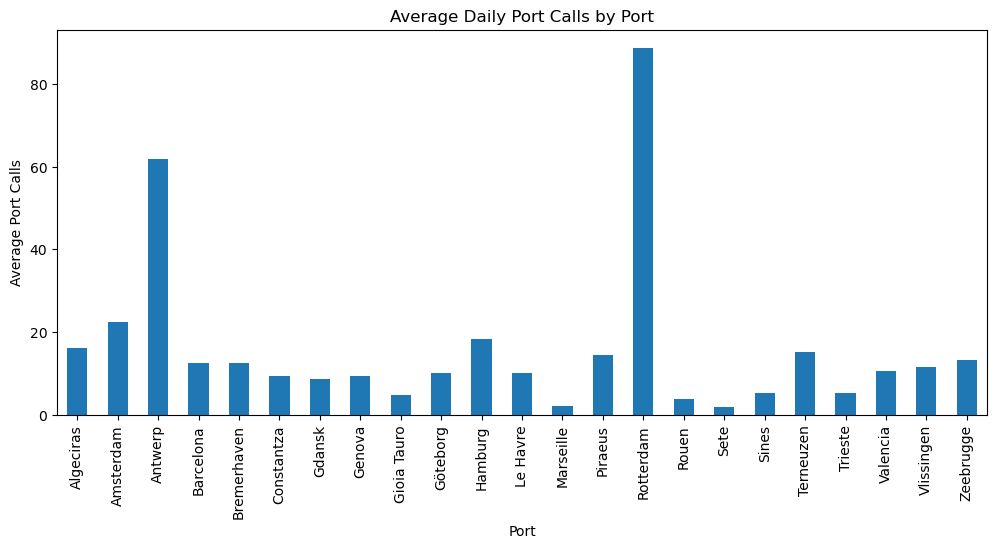

In [18]:
df.groupby('portname')['portcalls'].mean().plot(kind='bar', figsize=(12,5))

plt.title('Average Daily Port Calls by Port')
plt.xlabel('Port')
plt.ylabel('Average Port Calls')
plt.xticks(rotation=90)
plt.show()

In [19]:
monthly_portcalls = df.groupby(df['date'].dt.to_period('M'))['portcalls'].mean()

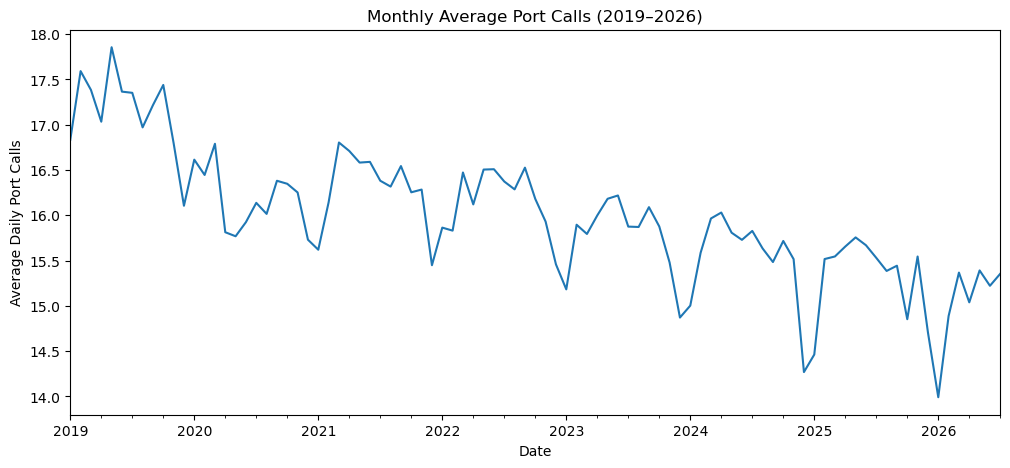

In [20]:
monthly_portcalls.plot(figsize=(12,5))

plt.title('Monthly Average Port Calls (2019–2026)')
plt.xlabel('Date')
plt.ylabel('Average Daily Port Calls')
plt.show()

In [21]:
df.groupby('month')['portcalls'].mean()

month
1     15.446353
2     15.987495
3     16.265252
4     16.050000
5     16.231066
6     16.153442
7     16.125744
8     16.068523
9     16.240580
10    16.095372
11    15.971843
12    15.227209
Name: portcalls, dtype: float64

In [22]:
df.groupby(['year', 'month'])['portcalls'].mean()

year  month
2019  1        16.833100
      2        17.591615
      3        17.384292
      4        17.033333
      5        17.855540
                 ...    
2026  3        15.367461
      4        15.039130
      5        15.391304
      6        15.221739
      7        15.355072
Name: portcalls, Length: 91, dtype: float64

In [23]:
df.groupby(['year', 'month'])['portcalls'].mean().head(12)

year  month
2019  1        16.833100
      2        17.591615
      3        17.384292
      4        17.033333
      5        17.855540
      6        17.365217
      7        17.352034
      8        16.970547
      9        17.215942
      10       17.438990
      11       16.797101
      12       16.105189
Name: portcalls, dtype: float64

In [24]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2020]

month
1     16.614306
2     16.445277
3     16.789621
4     15.813043
5     15.768583
6     15.924638
7     16.137447
8     16.015428
9     16.381159
10    16.347826
11    16.252174
12    15.730715
Name: portcalls, dtype: float64

In [25]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2021]

month
1     15.619916
2     16.142857
3     16.803647
4     16.710145
5     16.582048
6     16.589855
7     16.381487
8     16.316971
9     16.543478
10    16.253857
11    16.284058
12    15.448808
Name: portcalls, dtype: float64

In [26]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2022]

month
1     15.863955
2     15.830745
3     16.472651
4     16.120290
5     16.504909
6     16.508696
7     16.373072
8     16.286115
9     16.526087
10    16.180926
11    15.930435
12    15.458626
Name: portcalls, dtype: float64

In [27]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2023]

month
1     15.182328
2     15.895963
3     15.793829
4     15.998551
5     16.182328
6     16.218841
7     15.875175
8     15.870968
9     16.089855
10    15.876578
11    15.478261
12    14.870968
Name: portcalls, dtype: float64

In [28]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2024]

month
1     15.002805
2     15.586207
3     15.964937
4     16.030435
5     15.807854
6     15.728986
7     15.827489
8     15.633941
9     15.484058
10    15.716690
11    15.515942
12    14.269285
Name: portcalls, dtype: float64

In [29]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2025]

month
1     14.462833
2     15.517081
3     15.545582
4     15.655072
5     15.755961
6     15.669565
7     15.530154
8     15.385694
9     15.443478
10    14.852735
11    15.544928
12    14.706872
Name: portcalls, dtype: float64

In [30]:
df.groupby(['year', 'month'])['portcalls'].mean().loc[2026]

month
1    13.991585
2    14.888199
3    15.367461
4    15.039130
5    15.391304
6    15.221739
7    15.355072
Name: portcalls, dtype: float64

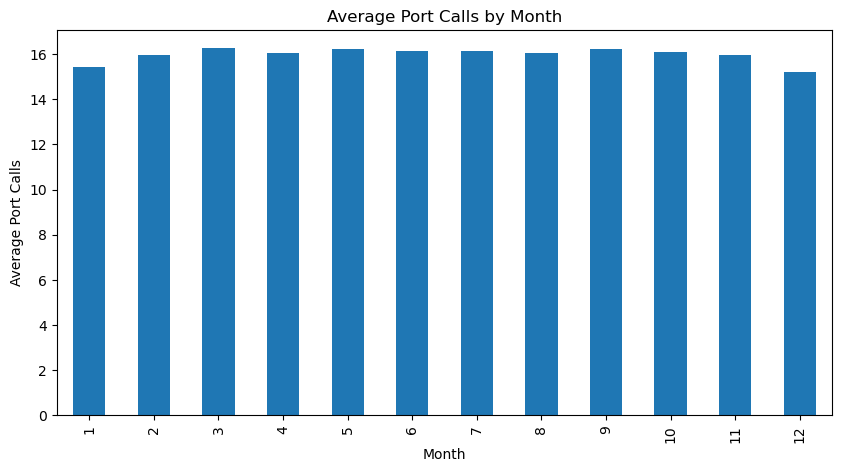

In [31]:
monthly_portcalls = df.groupby('month')['portcalls'].mean()

monthly_portcalls.plot(kind='bar', figsize=(10,5))
plt.title('Average Port Calls by Month')
plt.xlabel('Month')
plt.ylabel('Average Port Calls')
plt.show()

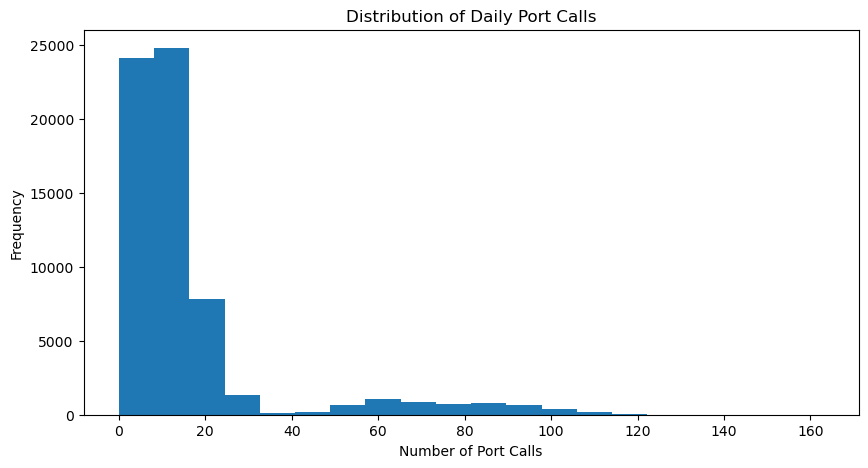

In [33]:
df['portcalls'].plot(kind='hist', bins=20, figsize=(10,5))

plt.title('Distribution of Daily Port Calls')
plt.xlabel('Number of Port Calls')
plt.ylabel('Frequency')
plt.show()

In [34]:
df['portcalls'].median()

11.0

In [35]:
(df['portcalls'] > 11).sum()

28760

In [36]:
p = (df['portcalls'] > 11).mean()
p

0.4527280168749803

In [37]:
n = 10
k = np.arange(0, n + 1)

binomial_probabilities = stats.binom.pmf(k, n, p)

binomial_probabilities

array([0.00241008, 0.0199373 , 0.07421864, 0.16372533, 0.23702168,
       0.23529   , 0.16220207, 0.07667477, 0.02378581, 0.0043726 ,
       0.00036172])

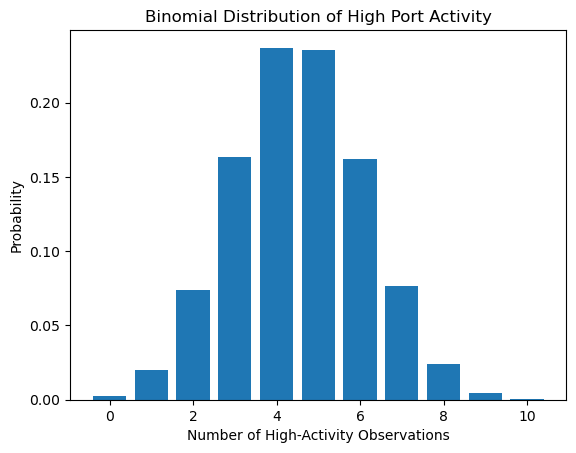

In [38]:
plt.bar(k, binomial_probabilities)

plt.title('Binomial Distribution of High Port Activity')
plt.xlabel('Number of High-Activity Observations')
plt.ylabel('Probability')

plt.show()

In [39]:
n_large = 100
k_large = np.arange(0, n_large + 1)

binomial_large = stats.binom.pmf(k_large, n_large, p)

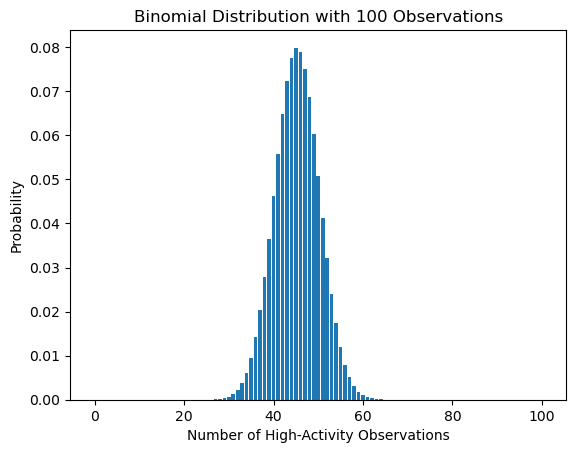

In [40]:
plt.bar(k_large, binomial_large)

plt.title('Binomial Distribution with 100 Observations')
plt.xlabel('Number of High-Activity Observations')
plt.ylabel('Probability')

plt.show()

In [41]:
lambda_value = df['portcalls'].mean()

lambda_value

15.990791172118502

In [42]:
k_poisson = np.arange(0, 41)

poisson_probabilities = stats.poisson.pmf(k_poisson, lambda_value)

poisson_probabilities

array([1.13576278e-07, 1.81617455e-06, 1.45210339e-05, 7.74009404e-05,
       3.09425569e-04, 9.89591931e-04, 2.63739299e-03, 6.02485721e-03,
       1.20427792e-02, 2.13970630e-02, 3.42155966e-02, 4.97394964e-02,
       6.62811583e-02, 8.15298586e-02, 9.31233531e-02, 9.92744061e-02,
       9.92172686e-02, 9.33272131e-02, 8.29097764e-02, 6.97785748e-02,
       5.57907309e-02, 4.24827584e-02, 3.08787690e-02, 2.14685194e-02,
       1.43041088e-02, 9.14936066e-03, 5.62713522e-03, 3.33267941e-03,
       1.90329216e-03, 1.04948785e-03, 5.59404699e-04, 2.88558830e-04,
       1.44196375e-04, 6.98731550e-05, 3.28625597e-05, 1.50142380e-05,
       6.66915401e-06, 2.88229862e-06, 1.21290093e-06, 4.97313987e-07,
       1.98811103e-07])

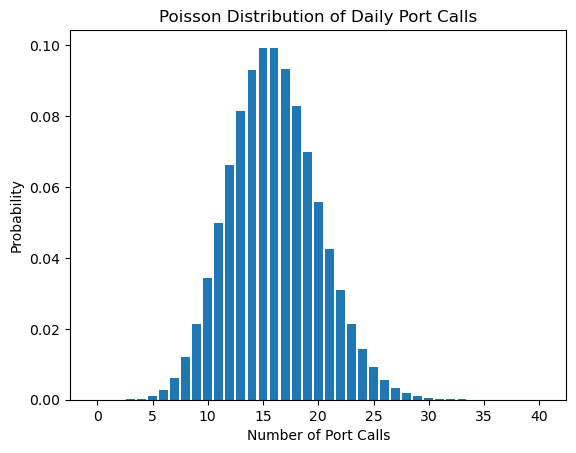

In [43]:
plt.bar(k_poisson, poisson_probabilities)

plt.title('Poisson Distribution of Daily Port Calls')
plt.xlabel('Number of Port Calls')
plt.ylabel('Probability')

plt.show()

In [44]:
mean_value = df['portcalls'].mean()
std_value = df['portcalls'].std()

print("Mean:", mean_value)
print("Standard deviation:", std_value)

Mean: 15.990791172118502
Standard deviation: 19.895840384013816


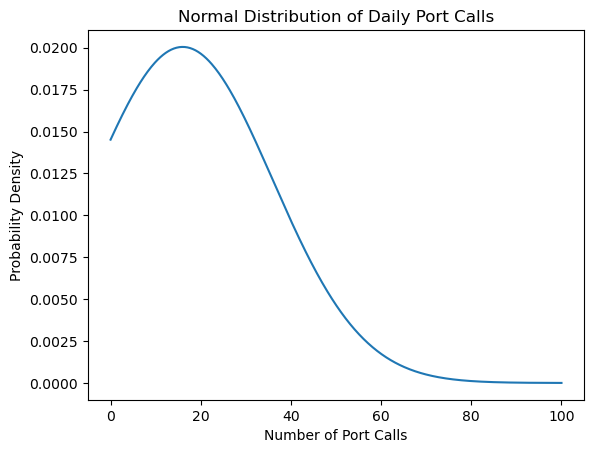

In [46]:
x = np.linspace(0, 100, 500)

normal_curve = stats.norm.pdf(x, mean_value, std_value)

plt.plot(x, normal_curve)

plt.title('Normal Distribution of Daily Port Calls')
plt.xlabel('Number of Port Calls')
plt.ylabel('Probability Density')

plt.show()